# 📊 01. Exploratory Data Analysis & Baseline Inefficiency Audit
### PreZero / Fillinq Challenge: AI-Driven Smart Waste Routing
**City of Heilbronn Municipal Glass Recycling Optimization**

This notebook performs data ingestion, cleaning, glass stream trajectory benchmarking, calendar & holiday impact analysis (Baden-Württemberg), and the baseline emptying efficiency audit.
Outputs are saved to `data/cleaned_fill_levels.csv` for downstream clustering and optimization.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_loader import load_and_clean_data

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['figure.dpi'] = 110
MAT_COLORS = {'white': '#1f77b4', 'green': '#2ca02c', 'brown': '#8c564b'}

print("Environment ready for Exploratory Data Analysis.")


Environment ready for Exploratory Data Analysis.


---
## 📥 1. Data Ingestion & Overview
Load dataset, strip BOM headers, parse dates, handle `'overfull'` readings (assigned $110\%$ for quantitative analysis), and integrate Baden-Württemberg public holidays.


In [2]:
df = load_and_clean_data("glass_fill_levels_anonymized_f.csv")
print(f"Total readings: {len(df):,} | Unique locations: {df['Location_id'].nunique()} | Span: {df['date'].min().date()} to {df['date'].max().date()}")
display(df.head(6))


Total readings: 11,701 | Unique locations: 449 | Span: 2025-10-17 to 2026-09-30


,Location_id,material_type,date,fill_level_perc,is_overfull,fill_num,year_month,day_name,day_of_week,week_number,is_holiday,holiday_name,prev_date,prev_fill,days_diff,fill_diff
0,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2025-10-31,100,False,100.0,2025-10,Friday,4,44,True,Pre-Allerheiligen (-1d),NaT,NaN,NaN,NaN
1,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2025-12-08,40,False,40.0,2025-12,Monday,0,50,False,Standard Regular Day,2025-10-31,100.0,38.0,-60.0
2,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2025-12-23,80,False,80.0,2025-12,Tuesday,1,52,True,Christmas / New Year Season,2025-12-08,40.0,15.0,40.0
3,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2026-02-25,60,False,60.0,2026-02,Wednesday,2,9,False,Standard Regular Day,2025-12-23,80.0,64.0,-20.0
4,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2026-04-14,100,False,100.0,2026-04,Tuesday,1,16,False,Standard Regular Day,2026-02-25,60.0,48.0,40.0
5,0004c095-29ec-4894-81a8-05f3a7a55650,brown,2026-05-18,100,False,100.0,2026-05,Monday,0,21,False,Standard Regular Day,2026-04-14,100.0,34.0,0.0


---
## 📈 2. Dataset Health Check & Core KPIs


In [3]:
n_records = len(df)
n_locations = df['Location_id'].nunique()
n_dates = df['date'].nunique()
span_days = (df['date'].max() - df['date'].min()).days
n_overfull = df['is_overfull'].sum()

summary_df = pd.DataFrame({
    'Metric': [
        'Total Recorded Readings',
        'Unique Container Locations',
        'Distinct Observation Dates',
        'Date Span Start',
        'Date Span End',
        'Total Duration (Days)',
        'Average Readings per Location',
        'Total Overfull Events',
        'Global Overfull Rate (%)',
        'Baden-Württemberg Holiday Window Observations'
    ],
    'Value': [
        f"{n_records:,}",
        f"{n_locations}",
        f"{n_dates}",
        f"{df['date'].min().date()}",
        f"{df['date'].max().date()}",
        f"{span_days} days (~{span_days/30.4:.1f} months)",
        f"{n_records / n_locations:.1f}",
        f"{n_overfull:,}",
        f"{(n_overfull / n_records)*100:.2f}%",
        f"{df['is_holiday'].sum():,} records in holiday/festive windows ({df['is_holiday'].mean()*100:.1f}%)"
    ]
})
display(summary_df)


,Metric,Value
0,Total Recorded Readings,"11,701"
1,Unique Container Locations,449
2,Distinct Observation Dates,229
3,Date Span Start,2025-10-17
4,Date Span End,2026-09-30
5,Total Duration (Days),348 days (~11.4 months)
6,Average Readings per Location,26.1
7,Total Overfull Events,"1,192"
8,Global Overfull Rate (%),10.19%
9,Baden-Württemberg Holiday Window Observations,"2,207 records in holiday/festive windows (18.9%)"


---
## ⚖️ 3. Material Stream Benchmark: White vs. Green vs. Brown Glass
The data reveals severe material disparity across container types.


In [4]:
mat_stats = []
for mat in ['white', 'green', 'brown']:
    sub = df[df['material_type'] == mat]
    mat_stats.append({
        'Material Stream': mat.capitalize() + ' Glass',
        'Total Readings': f"{len(sub):,}",
        'Share of All Readings': f"{len(sub)/len(df)*100:.1f}%",
        'Mean Fill (%)': f"{sub['fill_num'].mean():.1f}%",
        'Median Fill (%)': f"{sub['fill_num'].median():.1f}%",
        'Overfull Count': f"{sub['is_overfull'].sum():,}",
        'Overfull Rate (%)': f"{sub['is_overfull'].mean() * 100:.1f}%",
        'At or Above Capacity (>=100%)': f"{(sub['fill_num'] >= 100).mean() * 100:.1f}%",
        'Underfilled (<=30%)': f"{(sub['fill_num'] <= 30).mean() * 100:.1f}%"
    })

stream_comparison_df = pd.DataFrame(mat_stats).set_index('Material Stream')
display(stream_comparison_df)


,Total Readings,Share of All Readings,Mean Fill (%),Median Fill (%),Overfull Count,Overfull Rate (%),At or Above Capacity (>=100%),Underfilled (<=30%)
Material Stream,,,,,,,,
White Glass,"4,432",37.9%,82.2%,90.0%,731,16.5%,42.2%,4.8%
Green Glass,"4,169",35.6%,68.1%,70.0%,357,8.6%,24.7%,14.7%
Brown Glass,"3,100",26.5%,40.0%,30.0%,104,3.4%,7.9%,58.4%


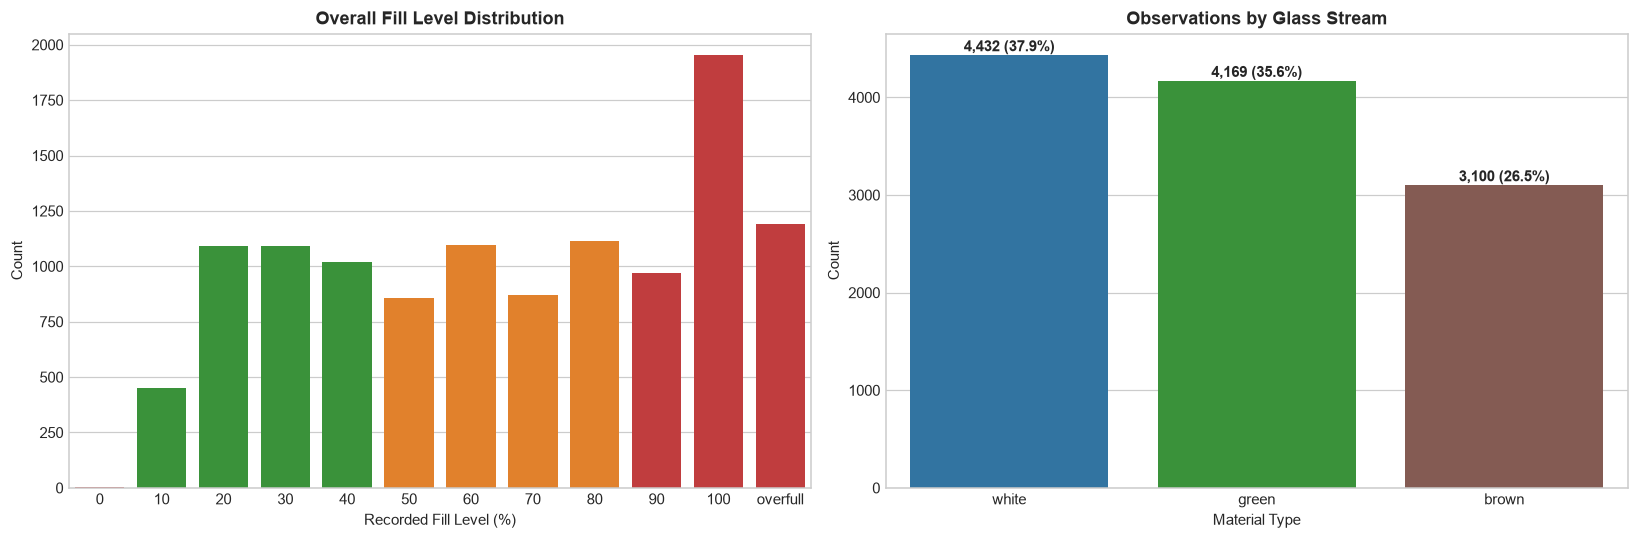

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Fill Level Distribution
fl_counts = df['fill_level_perc'].value_counts()
ordered_cats = ['0', '10', '20', '30', '40', '50', '60', '70', '80', '90', '100', 'overfull']
fl_ordered = fl_counts.reindex(ordered_cats).fillna(0)
bar_colors = ['#2ca02c' if c in ['10', '20', '30', '40'] else '#ff7f0e' if c in ['50', '60', '70', '80'] else '#d62728' for c in ordered_cats]

sns.barplot(x=fl_ordered.index, y=fl_ordered.values, ax=axes[0], palette=bar_colors)
axes[0].set_title("Overall Fill Level Distribution", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Recorded Fill Level (%)")
axes[0].set_ylabel("Count")

# 2. Material Breakdown
mat_counts = df['material_type'].value_counts()
sns.barplot(x=mat_counts.index, y=mat_counts.values, ax=axes[1], palette=[MAT_COLORS[m] for m in mat_counts.index])
axes[1].set_title("Observations by Glass Stream", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Material Type")
axes[1].set_ylabel("Count")
for i, (m, v) in enumerate(mat_counts.items()):
    axes[1].text(i, v + 40, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


---
## 📅 4. Calendar Dynamics & Holiday Impacts (Baden-Württemberg)
Examining weekly cycles and public holiday spikes (Christmas/New Year, Easter, Pentecost).


,Observations,Mean_Fill,Overfull_Rate
is_holiday,,,
Standard Regular Periods,9494,65.60,26.64
Holiday & Festive Windows (BW),2207,67.57,27.91


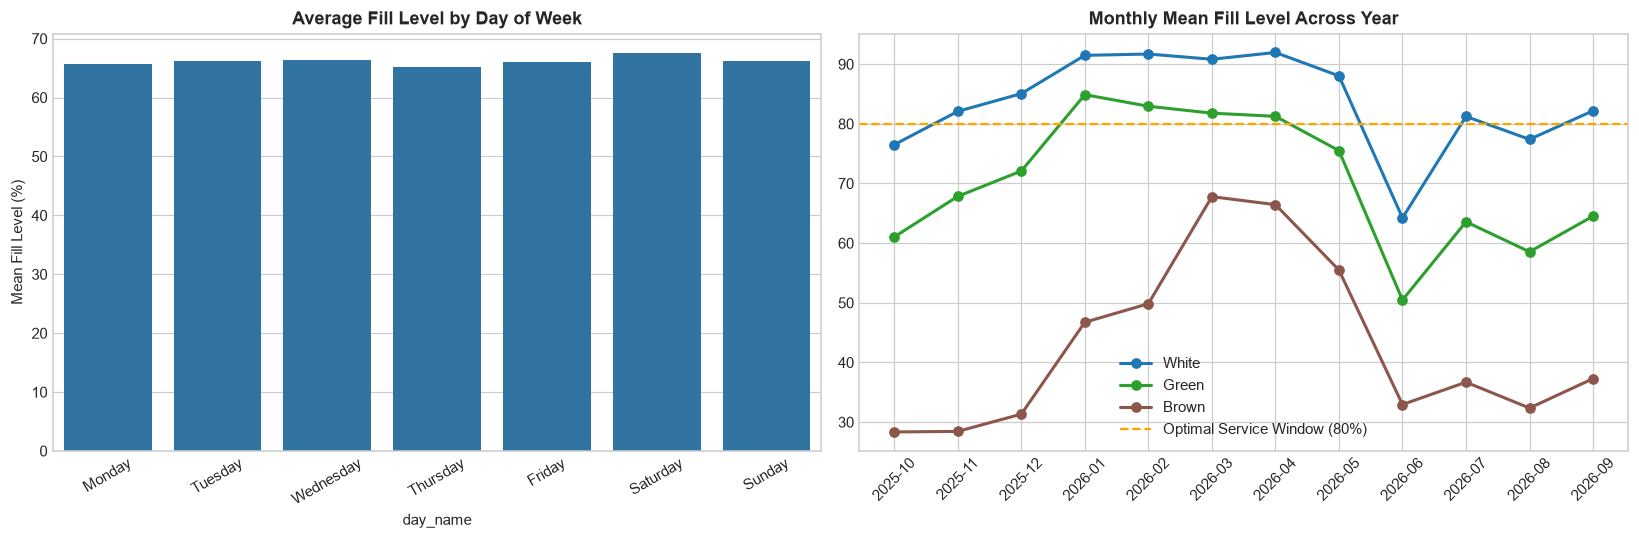

In [6]:
# Day of Week distribution
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_stats = df.groupby('day_name')['fill_num'].agg(mean='mean', overfull_rate=lambda x: (x >= 100).mean()*100).reindex(dow_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=dow_stats.index, y=dow_stats['mean'], ax=axes[0], color='#1f77b4')
axes[0].set_title("Average Fill Level by Day of Week", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Mean Fill Level (%)")
axes[0].tick_params(axis='x', rotation=30)

# Holiday vs Non-Holiday Comparison
holiday_comparison = df.groupby('is_holiday')['fill_num'].agg(
    Observations='count',
    Mean_Fill='mean',
    Overfull_Rate=lambda x: (x >= 100).mean() * 100
).rename(index={False: 'Standard Regular Periods', True: 'Holiday & Festive Windows (BW)'})
display(holiday_comparison.round(2))

# Monthly mean trajectory
monthly_stream = df.pivot_table(index='year_month', columns='material_type', values='fill_num', aggfunc='mean')
for mat in ['white', 'green', 'brown']:
    axes[1].plot(monthly_stream.index.astype(str), monthly_stream[mat], marker='o', linewidth=2, label=mat.capitalize(), color=MAT_COLORS[mat])
axes[1].axhline(80, color='orange', linestyle='--', label='Optimal Service Window (80%)')
axes[1].set_title("Monthly Mean Fill Level Across Year", fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()


---
## 📉 5. Inefficiency Diagnosis: Baseline Emptying Audit
Emptying events occur when fill level drops between consecutive readings ($\Delta F < 0$).
We audit container fill level immediately prior to being emptied:
* **Late / Overflow ($\ge 100\%$):** Urgent hazard, public complaints.
* **Optimal Window ($70\% - 90\%$):** Efficient payload, no overflow.
* **Premature ($40\% - 60\%$):** Suboptimal stop.
* **Highly Inefficient ($< 40\%$):** Wasted stop, empty run.


Total historical emptying events captured: 4,266


,Count,Share (%)
efficiency_class,,
Late / Overflow (>=100%),1895,44.4
Optimal Window (70-90%),1253,29.4
Premature (40-60%),788,18.5
Highly Inefficient (<40%),330,7.7


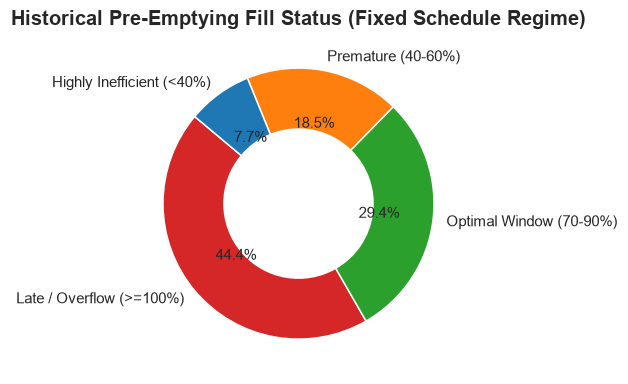

In [7]:
emptying_events = df[df['fill_diff'] < 0].copy()

def classify_emptying(prev_val):
    if prev_val >= 100:
        return 'Late / Overflow (>=100%)'
    elif prev_val >= 70:
        return 'Optimal Window (70-90%)'
    elif prev_val >= 40:
        return 'Premature (40-60%)'
    else:
        return 'Highly Inefficient (<40%)'

emptying_events['efficiency_class'] = emptying_events['prev_fill'].apply(classify_emptying)
eff_counts = emptying_events['efficiency_class'].value_counts()
eff_pct = emptying_events['efficiency_class'].value_counts(normalize=True) * 100

print(f"Total historical emptying events captured: {len(emptying_events):,}")
eff_summary = pd.DataFrame({'Count': eff_counts, 'Share (%)': eff_pct.round(1)})
display(eff_summary)

plt.figure(figsize=(8, 4))
eff_colors = {'Late / Overflow (>=100%)': '#d62728', 'Optimal Window (70-90%)': '#2ca02c', 
              'Premature (40-60%)': '#ff7f0e', 'Highly Inefficient (<40%)': '#1f77b4'}
plt.pie(eff_pct, labels=eff_pct.index, autopct='%1.1f%%', colors=[eff_colors[k] for k in eff_pct.index],
        wedgeprops=dict(width=0.45, edgecolor='w'), startangle=140)
plt.title("Historical Pre-Emptying Fill Status (Fixed Schedule Regime)", fontsize=13, fontweight='bold')
plt.show()


---
## 💾 6. Export Cleaned Data
Save cleaned and enriched data to `data/cleaned_fill_levels.csv` for the next notebooks.


In [8]:
os.makedirs("data", exist_ok=True)
output_path = os.path.join("data", "cleaned_fill_levels.csv")
df.to_csv(output_path, index=False)
print(f"Cleaned dataset successfully saved to: {output_path} ({len(df):,} rows)")


Cleaned dataset successfully saved to: data\cleaned_fill_levels.csv (11,701 rows)
